# deps

In [ ]:
# get the version of the package use
import sys

import matplotlib
import matplotlib.pyplot as pyplot
import pandas as pd
import scipy

print("python     :", sys.version.split(' ')[0])
for module in (matplotlib, pd, scipy):
    print(f"{module.__name__:<11}:", module.__version__)

python     : 3.13.5
matplotlib : 3.11.2
pandas     : 3.1.1
scipy      : 1.18.1


# Constant

In [72]:
# data file name
DATA_PATH = "../data"
CSV_RAW = "boardGamesRaw.csv"
CSV_CLEAN = "boardGamesClean.csv"

#column name
TITLE = "Title"

ORIGINAL_TYPE = "Type 1"
TYPE = "Type"

COMPLEXITY = "Complexity"

MEAN_TIME = "Mean time"
MIN_TIME = "Min time"
MAX_TIME = "Max time"

ORIGINAL_AVERAGE_RATING = "Avg rating"
AVERAGE_RATING = "Average rating"

ORIGINAL_NUMBER_VOTE = "Num of voters"
NUMBER_VOTE = "Number of voters"

POPULARITY = "Popularity"

# other const
SIGNIFICATIF_VOTE_NUMBER = 1000

# Loading, cleaning and calculate data

## loading the raw dataSet

In [73]:
rawDataFrame = pd.read_csv(f"{DATA_PATH}/{CSV_RAW}")
print(rawDataFrame.shape)

(25339, 14)


## cleaning the raw data

In [74]:
# 1. rename all column
rawDataFrame = rawDataFrame.rename(columns={
    ORIGINAL_TYPE: TYPE,
    ORIGINAL_AVERAGE_RATING: AVERAGE_RATING,
    ORIGINAL_NUMBER_VOTE: NUMBER_VOTE
})

In [75]:
# 2. Keep usefull columns
cols = [TITLE, AVERAGE_RATING, MIN_TIME, MAX_TIME, NUMBER_VOTE, COMPLEXITY, TYPE]
rawDataFrame = rawDataFrame[cols]

print(rawDataFrame.shape)

(25339, 7)


In [76]:
# 3. Delete lines with no values
rawDataFrame = rawDataFrame.dropna(subset=cols)
print(rawDataFrame.shape)

(12987, 7)


In [77]:
# 4. Keep lines with Complexity above 0
rawDataFrame = rawDataFrame[rawDataFrame[COMPLEXITY] > 0]
print(rawDataFrame.shape)

(12963, 7)


In [78]:
# 5. Save cleaned dataset
rawDataFrame.to_csv(f"{DATA_PATH}/{CSV_CLEAN}", index=False)
print(rawDataFrame.shape)

(12963, 7)


## Load clean data set

In [79]:
print(f"{DATA_PATH}/{CSV_CLEAN}")
cleanDataFrame = pd.read_csv(f"{DATA_PATH}/{CSV_CLEAN}")
print(cleanDataFrame.shape)

../data/boardGamesClean.csv
(12963, 7)


## calculate usefull value

In [80]:
fullDataFrame = cleanDataFrame.copy()

### mean time

In [81]:
# Calculate the mean time
fullDataFrame[MEAN_TIME] = (fullDataFrame[MIN_TIME] + fullDataFrame[MAX_TIME]) / 2
print(fullDataFrame.shape)

(12963, 8)


### Popularity

In [82]:
# caclculate the popularity
fullDataFrame[POPULARITY] = (fullDataFrame[NUMBER_VOTE]/fullDataFrame[NUMBER_VOTE] + SIGNIFICATIF_VOTE_NUMBER) * fullDataFrame[AVERAGE_RATING]
print(fullDataFrame.shape)

(12963, 9)


## organise data set for calcul

In [83]:
# round all value to 2
fullDataFrame = fullDataFrame.round(2)

#sort
fullDataFrame = fullDataFrame.sort_values(by=POPULARITY, ascending=True).reset_index(drop=True)

# generic function

In [84]:
#! function to show the evolution of a column by a graph

def evolutionGraph(rowName, dataFrame = fullDataFrame, graphTitle=None, sort=True):
    if graphTitle is None:
        graphTitle = f"evolution of {rowName}"

    # take the values of the column sort it and add it to the graph
    if(sort) :
        pyplot.plot(dataFrame[rowName].sort_values(ascending=True).reset_index(drop=True), color="b", marker=".", linestyle="none")
    else :
        pyplot.plot(dataFrame[rowName], color="b", marker=".", linestyle="none")

    # set the title
    pyplot.title(graphTitle) 
    # set the label of the x axe
    pyplot.xlabel("Game Index")
    # set the label of the y axe
    pyplot.ylabel(rowName)
    # add a grib to the graph
    pyplot.grid(True)

In [85]:
#! function to show a graph of Y by X and allow adding a line to the graph

def yByXGraph(rowNameX, rowNameY, dataFrame = fullDataFrame, graphTitle=None, sort=True, lineParams=None):
    # set the title if not already define
    if graphTitle is None:
        graphTitle = f"{rowNameY} by {rowNameX}"

    # drop all column that will not be use
    plotDf = dataFrame[[rowNameX, rowNameY]].dropna()
    # sort the value if it's ask
    if sort:
        plotDf = plotDf.sort_values(by=rowNameX, ascending=True)

    x = plotDf[rowNameX]
    y = plotDf[rowNameY]

    # add all value to the plot    
    pyplot.plot(x, y, color="b", marker=".", linestyle="none")

    # add the line if require
    if lineParams is not None and not plotDf.empty:
        # get b0 and b1
        b0, b1 = lineParams
        # get the min and max x value
        xMin = float(x.min())
        xMax = float(x.max())
        xPoints = [xMin, xMax]
        # calculate the y min and max value
        yPoints = [b0 + b1 * xMin, b0 + b1 * xMax]
        pyplot.plot(xPoints, yPoints, color="r", linestyle="--")

    # set the title
    pyplot.title(graphTitle) 
    # set the label of the x axe
    pyplot.xlabel(rowNameX)
    # set the label of the y axe
    pyplot.ylabel(rowNameY)
    # add a grib to the graph
    pyplot.grid(True)

In [86]:
#! function to make a boxplot of a column

def boxplot(rowName, dataFrame = fullDataFrame, whis=(0, 100), graphTitle=None):
    # generate the title if is not provided
    if graphTitle is None:
        graphTitle = f"boxplot of {rowName}"

    #take the values of the column and make a boxplot
    pyplot.boxplot(dataFrame[rowName], whis=whis)

    # set the title
    pyplot.title(graphTitle) 
    # set the label of the x axe
    pyplot.xlabel("Distribution")
    # set the label of the y axe
    pyplot.ylabel(rowName)
    # show the graph
    pyplot.grid(True)

    #  calculate all the quartile and the min/max value
    minVal = dataFrame[rowName].quantile(0)
    q1 = dataFrame[rowName].quantile(0.25)
    q2 = dataFrame[rowName].quantile(0.50)
    q3 = dataFrame[rowName].quantile(0.75)
    maxVal = dataFrame[rowName].quantile(1)
    iqr = q3 - q1;

    # create a string with all the stats
    statsText = (
        f"MAX: {maxVal:.2f}\n"
        f"Q3:  {q3:.2f}\n"
        f"Q2:  {q2:.2f}\n"
        f"Q1:  {q1:.2f}\n"
        f"MIN: {minVal:.2f}\n"
        f"IQR: {iqr:.2f}"
    )

    # display text on the graph
    pyplot.text(
        0.03, 0.05, statsText,
        # say to place the text relatively
        transform=pyplot.gca().transAxes,
        fontsize=9, 
        verticalalignment='bottom',
        horizontalalignment='left',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='gray')
    )

    

In [87]:
#! function to make a bar graph

def barGraph(rowName, valueColumn=None, dataFrame = fullDataFrame, agg_func='mean', color="skyblue", graphTitle=None, showText=False, onConsole=True):
    # generate the title if is not provided
    if graphTitle is None:
        if valueColumn is None:
            graphTitle = f"Number of {rowName}"
        else:
            graphTitle = f"{agg_func.capitalize()} of {valueColumn} by {rowName}"

    # process data depending on whether a value column is specified
    if valueColumn is None:
        dataPlot = dataFrame[rowName].value_counts().sort_values()
        yLabel = f"Number of {rowName}"
    else:
        dataPlot = dataFrame.groupby(rowName)[valueColumn].agg(agg_func).sort_values()
        yLabel = f"{agg_func.capitalize()} of {valueColumn}"

    # Create the plot
    dataPlot.plot(kind="bar", color=color)

    # set title
    pyplot.title(graphTitle) 
    # set the label of the x axe
    pyplot.xlabel(rowName)
    # set the label of the y axe
    pyplot.ylabel(yLabel)
    # rotate the x values name
    pyplot.xticks(rotation=45, ha="right")
    
    # format data stats
    formattedLines = []

    # travel all items to get it's key and it's value
    for key, value in dataPlot.items():
        
        # check if is a float or not
        if isinstance(value, float):
            # round to 2
            line = f"{key}: {value:.2f}"
        else:
            line = f"{key}: {value}"
            
        # add the line to the list
        formattedLines.append(line)

    # join each part of the list with \n
    statsText = "\n".join(formattedLines)

    # show the stat
    if(showText):
        pyplot.text(
            0.03, 0.95, statsText,
            fontsize=8, 
            # say to place the text relatively
            transform=pyplot.gca().transAxes,
            verticalalignment='top',
            horizontalalignment='left',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='gray')
        )

    pyplot.tight_layout() 

    if(onConsole):
        print(statsText)

# Get Global information

In [ ]:
print("rows, columns:", fullDataFrame.shape)
fullDataFrame.info()
# show rows
fullDataFrame.head(fullDataFrame.shape[0])

rows, columns: (12963, 9)
<class 'pandas.DataFrame'>
RangeIndex: 12963 entries, 0 to 12962
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Title             12963 non-null  str    
 1   Average rating    12963 non-null  float64
 2   Min time          12963 non-null  float64
 3   Max time          12963 non-null  float64
 4   Number of voters  12963 non-null  int64  
 5   Complexity        12963 non-null  float64
 6   Type              12963 non-null  str    
 7   Mean time         12963 non-null  float64
 8   Popularity        12963 non-null  float64
dtypes: float64(6), int64(1), str(2)
memory usage: 911.6 KB


,Title,Average rating,Min time,Max time,Number of voters,Complexity,Type,Mean time,Popularity
0,Super Deck!,2.13,20.0,20.0,79,1.40,Customizable,20.0,2132.13
1,Quidditch: The Game,2.85,30.0,30.0,95,1.67,Children's,30.0,2852.85
2,Warmaster Chess 2000,2.86,60.0,60.0,52,2.50,Wargames,60.0,2862.86
3,The Civil War: The War That Pitted Brother Aga...,2.99,1200.0,1200.0,53,3.22,Wargames,1200.0,2992.99
4,"Civil War Classics, Volume 1: The Battles of P...",3.30,240.0,240.0,35,3.00,Wargames,240.0,3303.30
...,...,...,...,...,...,...,...,...,...
12958,Wings of the Motherland,9.24,60.0,240.0,117,4.33,Wargames,150.0,9249.24
12959,Malhya: Lands of Legends,9.24,60.0,180.0,144,3.42,Thematic,120.0,9249.24
12960,On to Richmond II: The Union Strikes South,9.29,60.0,1200.0,61,4.33,Wargames,630.0,9299.29
12961,1985: Sacred Oil,9.40,300.0,3000.0,38,4.50,Wargames,1650.0,9409.40


In [89]:
# count = number of row fill with a value
# mean = mean of all the value
cross_table = pd.pivot_table(
    fullDataFrame,
    values=[AVERAGE_RATING, NUMBER_VOTE],
    index=[TYPE],
    aggfunc={"mean", "count"},
).round(2)

print(cross_table)

             Average rating       Number of voters         
                      count  mean            count     mean
Type                                                       
Abstract               1322  6.29             1322   944.89
Children's              945  5.69              945   358.33
Customizable            334  6.53              334  1351.55
Family                 2773  6.47             2773  2628.03
Party                   685  6.32              685  2349.20
Strategy               2334  7.02             2334  3211.97
Thematic               1107  6.92             1107  2148.45
Wargames               3463  6.94             3463   229.22


## evolution graph

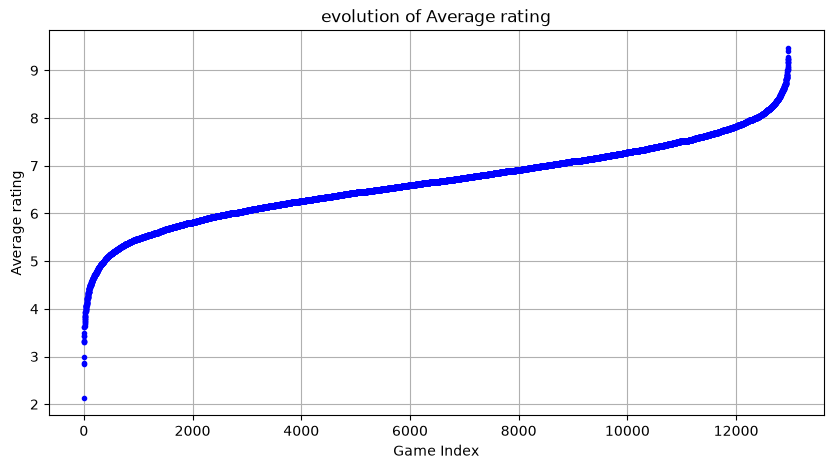

In [90]:
#! graph show the evolution of the average rating

# set the size of the graph
pyplot.figure(figsize=(10, 5))
evolutionGraph(AVERAGE_RATING)
pyplot.show()

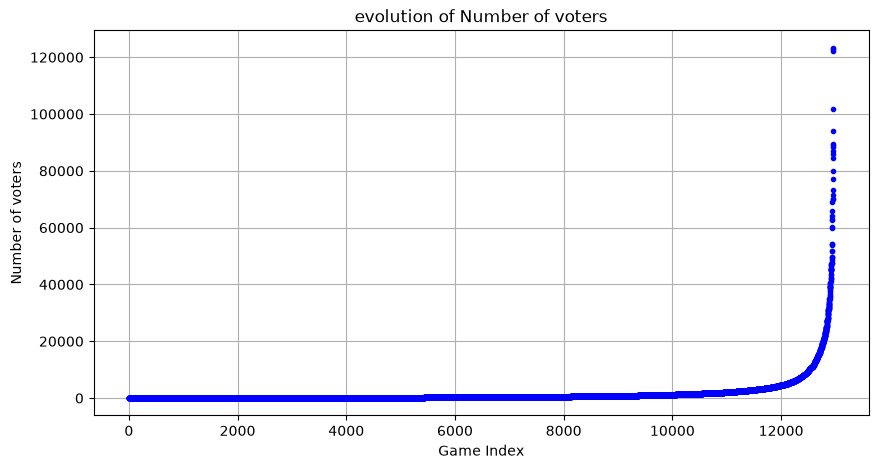

In [105]:
#! graph show the evolution of the popularity

# set the size of the graph
pyplot.figure(figsize=(10, 5))
evolutionGraph(NUMBER_VOTE)
pyplot.show()

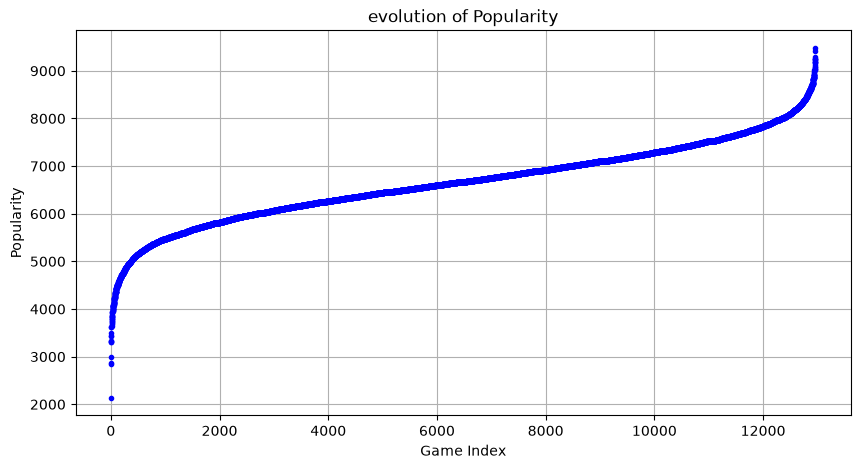

In [ ]:
#! graph show the evolution of the popularity

# set the size of the graph
pyplot.figure(figsize=(10, 5))
evolutionGraph(POPULARITY)
pyplot.show()

## boxplot

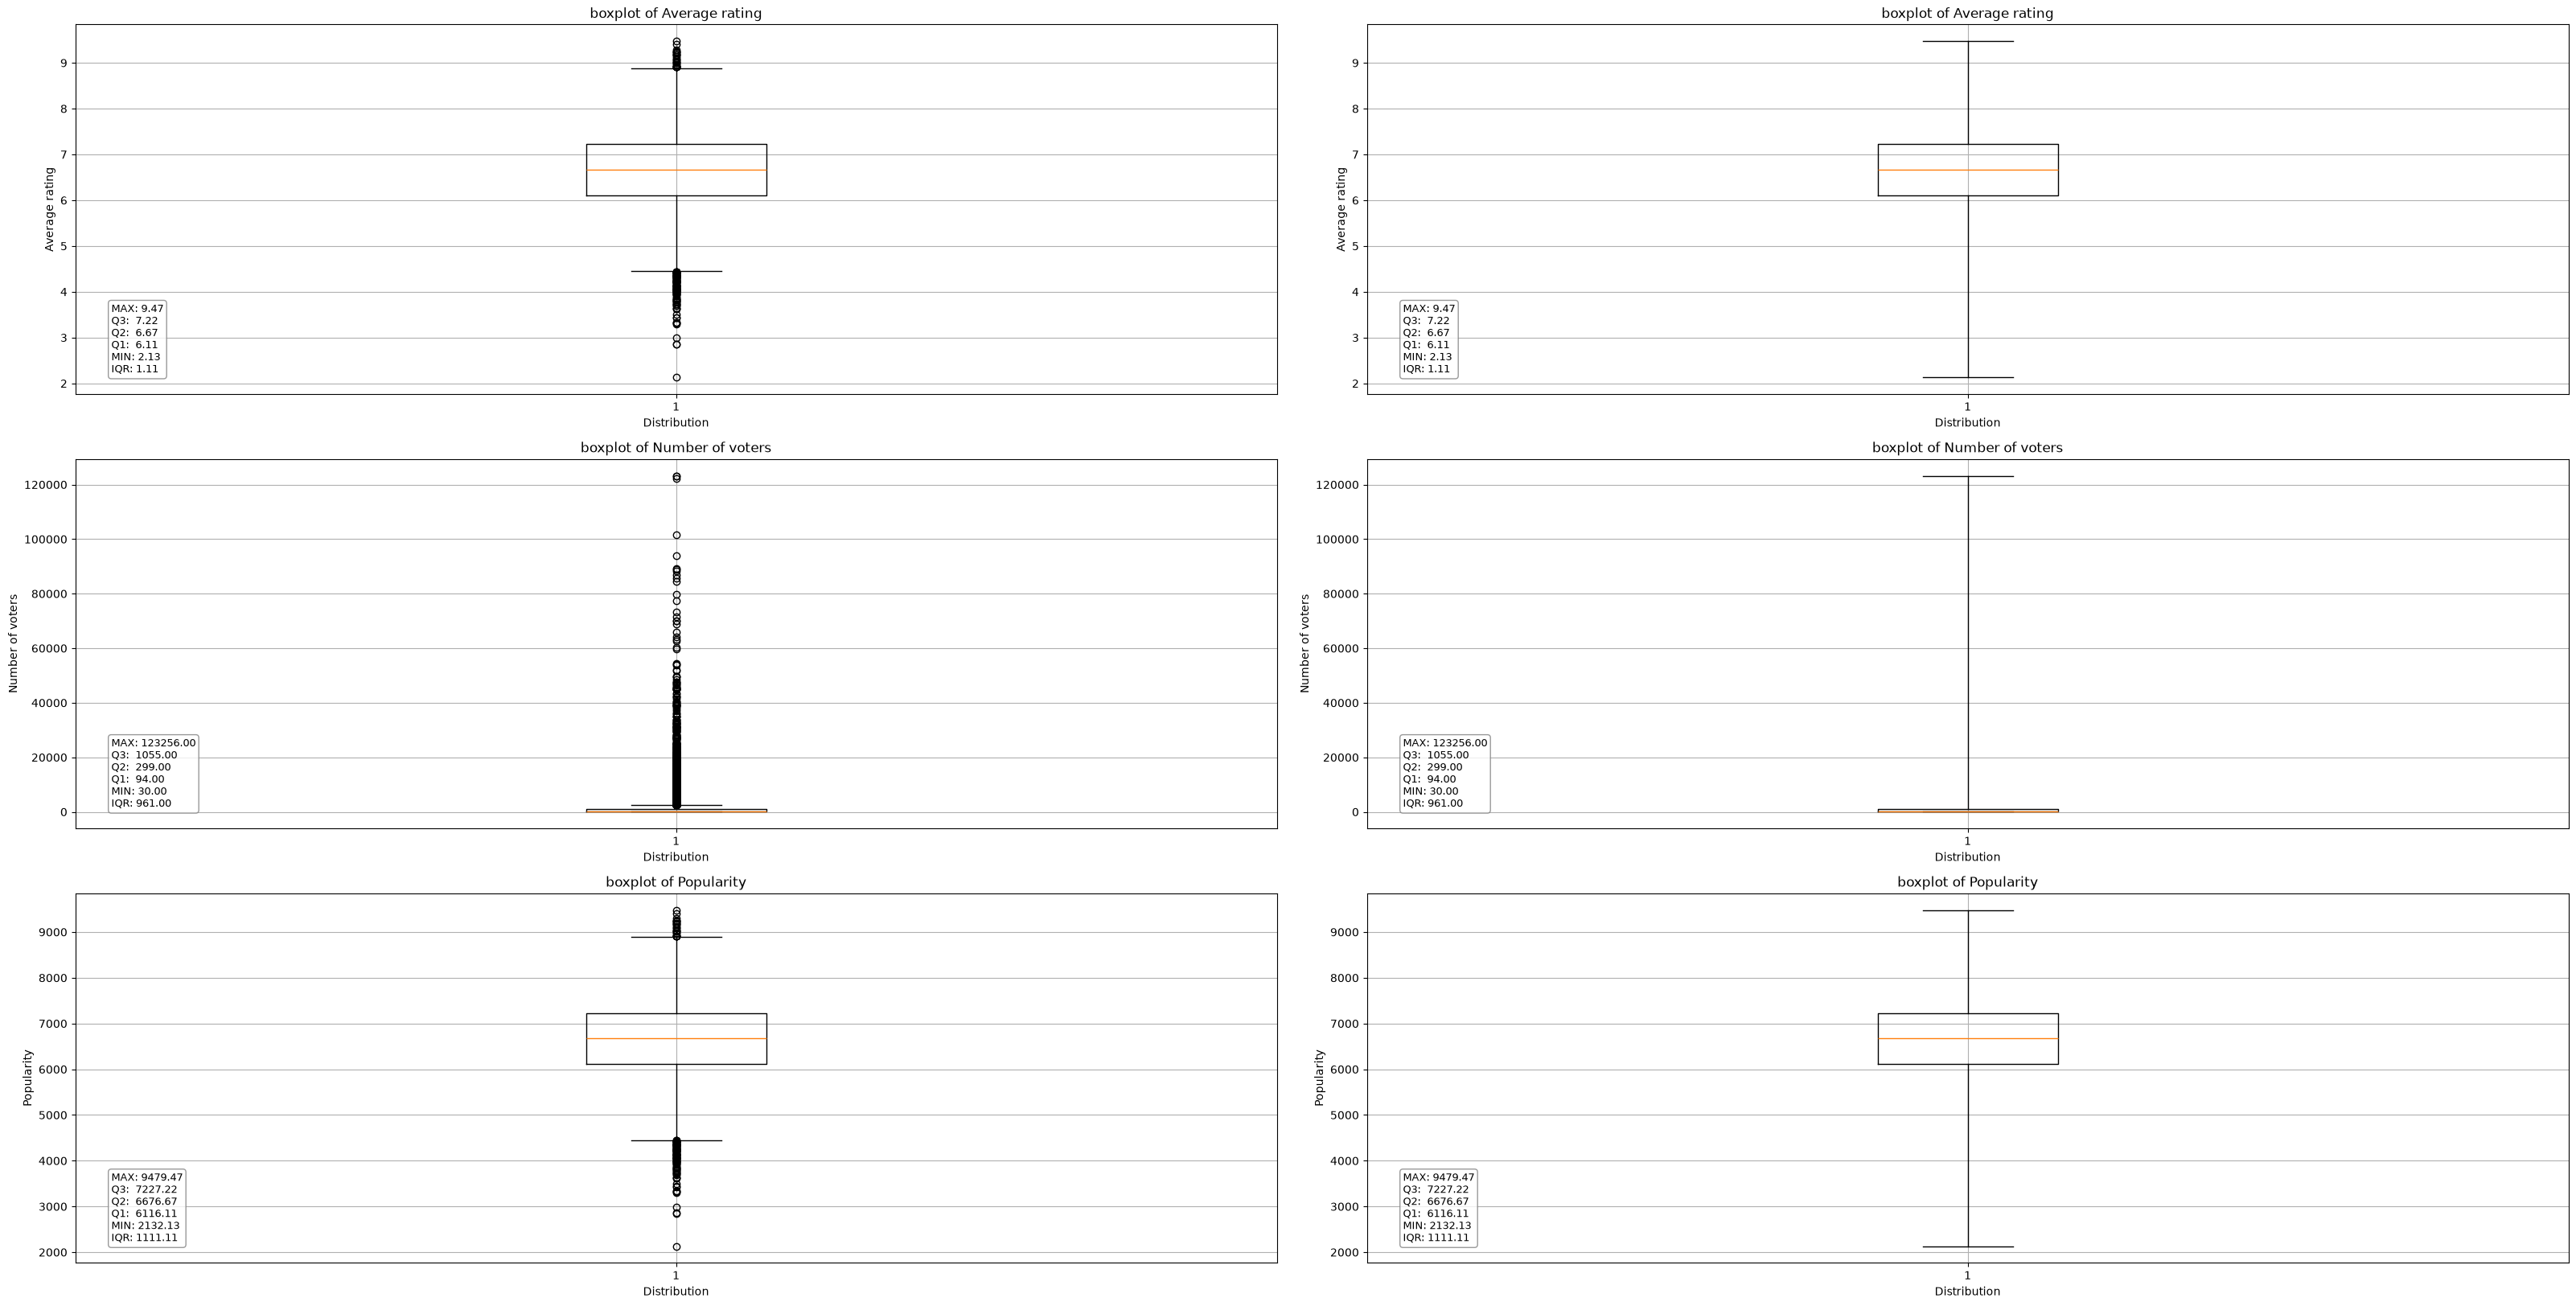

In [92]:
# graph show the evolution of the average rating
pyplot.figure(figsize=(40, 20))

pyplot.subplot(3, 2, 1)

boxplot(AVERAGE_RATING, whis=1.5)

pyplot.subplot(3, 2, 2)

boxplot(AVERAGE_RATING)

pyplot.subplot(3, 2, 3)

boxplot(NUMBER_VOTE, whis=1.5)

pyplot.subplot(3, 2, 4)

boxplot(NUMBER_VOTE)

pyplot.subplot(3, 2, 5)

boxplot(POPULARITY, whis=1.5)
pyplot.subplot(3, 2, 6)

boxplot(POPULARITY)

pyplot.subplots_adjust(wspace=0.075, hspace=0.175)
pyplot.show()

## number of value out of the box

In [93]:
# Liste des colonnes à analyser
columns_to_check = [AVERAGE_RATING, NUMBER_VOTE, POPULARITY]

for col in columns_to_check:
    # Calcul de Q1 (25e percentile) et Q3 (75e percentile)
    Q1 = fullDataFrame[col].quantile(0.25)
    Q3 = fullDataFrame[col].quantile(0.75)
    
    # Calcul de l'écart interquartile (IQR)
    IQR = Q3 - Q1
    
    # Seuils inférieur et supérieur
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Compter les valeurs en dessous et au-dessus des seuils
    count_lower_outliers = (fullDataFrame[col] < lower_bound).sum()
    count_upper_outliers = (fullDataFrame[col] > upper_bound).sum()
    
    print(f"--- {col} ---")
    print(f"  Valeurs < Q1 - 1.5*IQR (en dessous) : {count_lower_outliers} (Seuil : {lower_bound:.2f})")
    print(f"  Valeurs > Q3 + 1.5*IQR (au-dessus)  : {count_upper_outliers} (Seuil : {upper_bound:.2f})")

--- Average rating ---
  Valeurs < Q1 - 1.5*IQR (en dessous) : 106 (Seuil : 4.45)
  Valeurs > Q3 + 1.5*IQR (au-dessus)  : 26 (Seuil : 8.88)
--- Number of voters ---
  Valeurs < Q1 - 1.5*IQR (en dessous) : 0 (Seuil : -1347.50)
  Valeurs > Q3 + 1.5*IQR (au-dessus)  : 1674 (Seuil : 2496.50)
--- Popularity ---
  Valeurs < Q1 - 1.5*IQR (en dessous) : 106 (Seuil : 4449.44)
  Valeurs > Q3 + 1.5*IQR (au-dessus)  : 26 (Seuil : 8893.89)


## bar graph

Customizable: 334
Party: 685
Children's: 945
Thematic: 1107
Abstract: 1322
Strategy: 2334
Family: 2773
Wargames: 3463


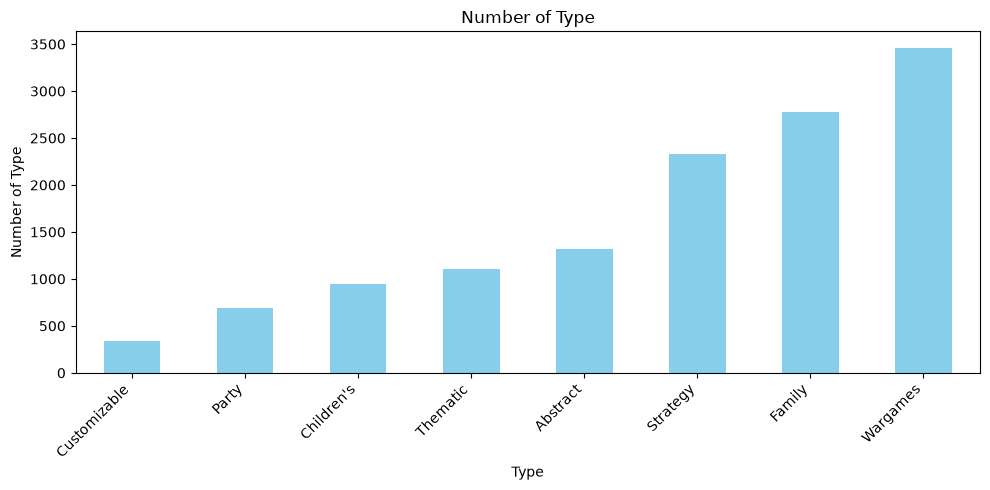

In [94]:
#! show bar graph with the number of element for a type
pyplot.figure(figsize=(10, 5))

barGraph(TYPE, color="skyblue")
pyplot.show()

Children's: 21.96
Abstract: 28.48
Party: 34.54
Family: 38.02
Customizable: 46.38
Thematic: 86.75
Strategy: 88.85
Wargames: 264.10


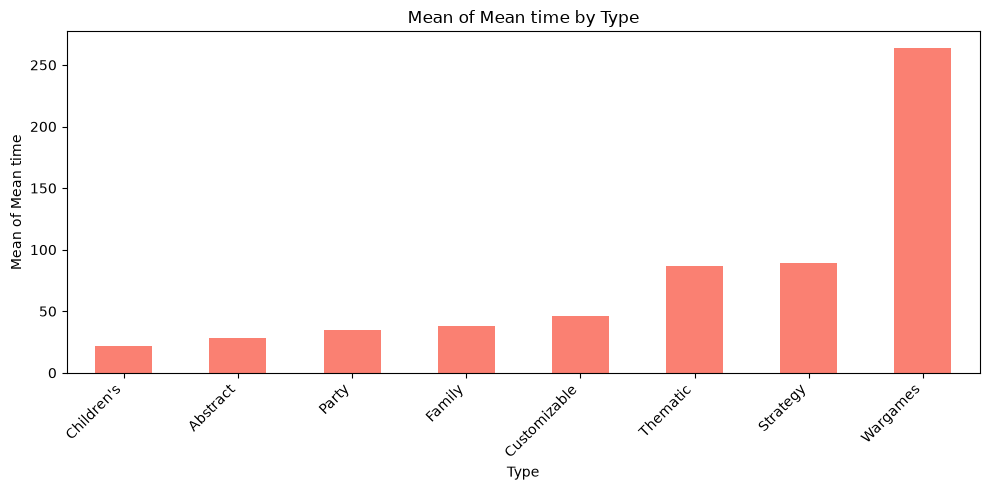

In [95]:
#! show a bar graph with the mean time by type
pyplot.figure(figsize=(10, 5))

barGraph(TYPE, valueColumn=MEAN_TIME, agg_func='mean', color="salmon")
pyplot.show()

Children's: 5.69
Abstract: 6.29
Party: 6.32
Family: 6.47
Customizable: 6.53
Thematic: 6.92
Wargames: 6.94
Strategy: 7.02


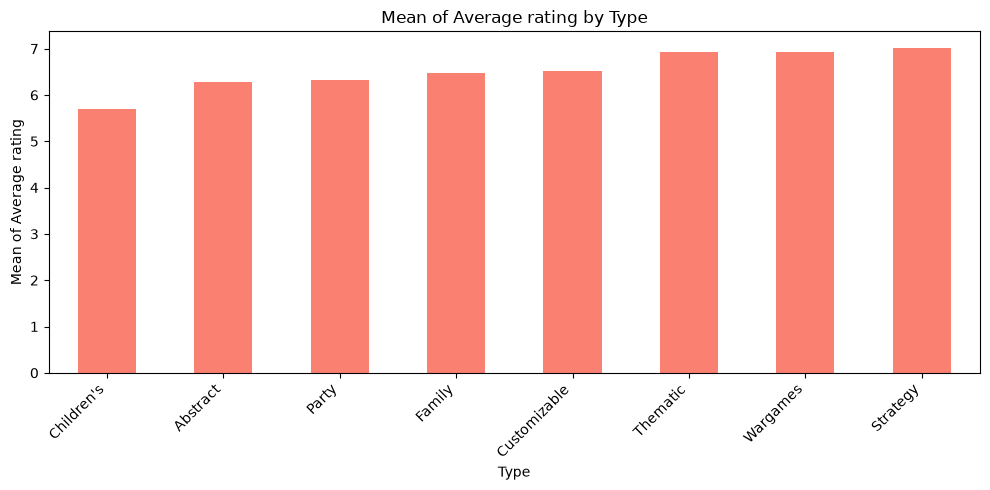

In [96]:
#! mean of the rating by type
pyplot.figure(figsize=(10, 5))

barGraph(TYPE, valueColumn=AVERAGE_RATING, agg_func='mean', color="salmon")
pyplot.show()

# make a dataFrame with popular only

In [97]:
#! remove popular game
popularDataFrame = fullDataFrame[fullDataFrame[POPULARITY] > fullDataFrame[POPULARITY].quantile(0.75)]
print(f"{popularDataFrame.shape[0]}\n{round(popularDataFrame.shape[0]/fullDataFrame.shape[0], 4)*100}%")
print(f"{round(popularDataFrame.shape[0]/fullDataFrame.shape[0], 4)*100}%")

3216
24.81%
24.81%


In [98]:
# pd.set_option('display.max_rows', None)
# pandas.set_option('display.max_columns', None)

popularDataFrame.sort_values(by=POPULARITY, ascending=True).reset_index(drop=True).head(popularDataFrame.shape[0])

,Title,Average rating,Min time,Max time,Number of voters,Complexity,Type,Mean time,Popularity
0,Champions of Hara,7.23,30.0,120.0,464,3.14,Strategy,75.0,7237.23
1,Rescue Polar Bears: Data & Temperature,7.23,30.0,60.0,617,2.33,Family,45.0,7237.23
2,Wonder Woman: Challenge of the Amazons,7.23,45.0,60.0,585,2.28,Thematic,52.5,7237.23
3,Judean Hammer,7.23,60.0,90.0,58,2.40,Wargames,75.0,7237.23
4,San Juan,7.23,45.0,60.0,23578,2.29,Strategy,52.5,7237.23
...,...,...,...,...,...,...,...,...,...
3211,Wings of the Motherland,9.24,60.0,240.0,117,4.33,Wargames,150.0,9249.24
3212,Malhya: Lands of Legends,9.24,60.0,180.0,144,3.42,Thematic,120.0,9249.24
3213,On to Richmond II: The Union Strikes South,9.29,60.0,1200.0,61,4.33,Wargames,630.0,9299.29
3214,1985: Sacred Oil,9.40,300.0,3000.0,38,4.50,Wargames,1650.0,9409.40


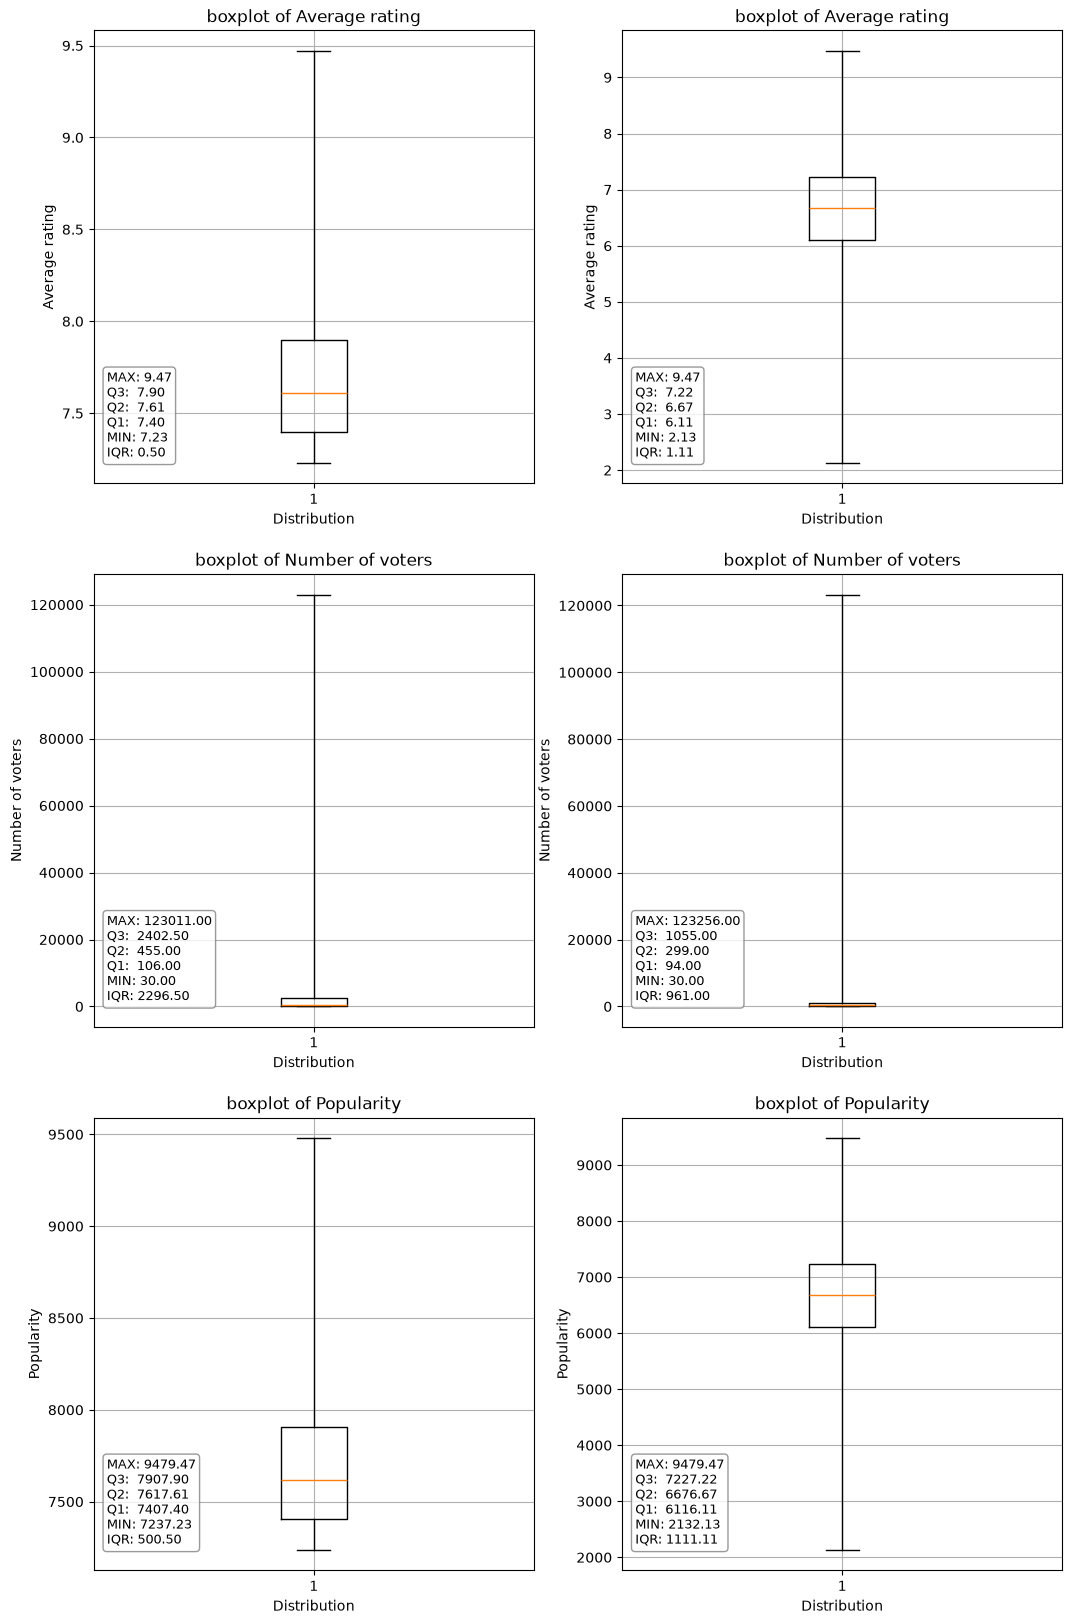

In [99]:
#! boxplot of rating, number of vote and popularity only with popular game
pyplot.figure(figsize=(12.5, 20))

pyplot.subplot(3, 2, 1)
boxplot(AVERAGE_RATING, dataFrame=popularDataFrame)

pyplot.subplot(3, 2, 3)
boxplot(NUMBER_VOTE, dataFrame=popularDataFrame)

pyplot.subplot(3, 2, 5)
boxplot(POPULARITY, dataFrame=popularDataFrame)


pyplot.subplot(3, 2, 2)
boxplot(AVERAGE_RATING)

pyplot.subplot(3, 2, 4)
boxplot(NUMBER_VOTE)

pyplot.subplot(3, 2, 6)
boxplot(POPULARITY)



pyplot.show()

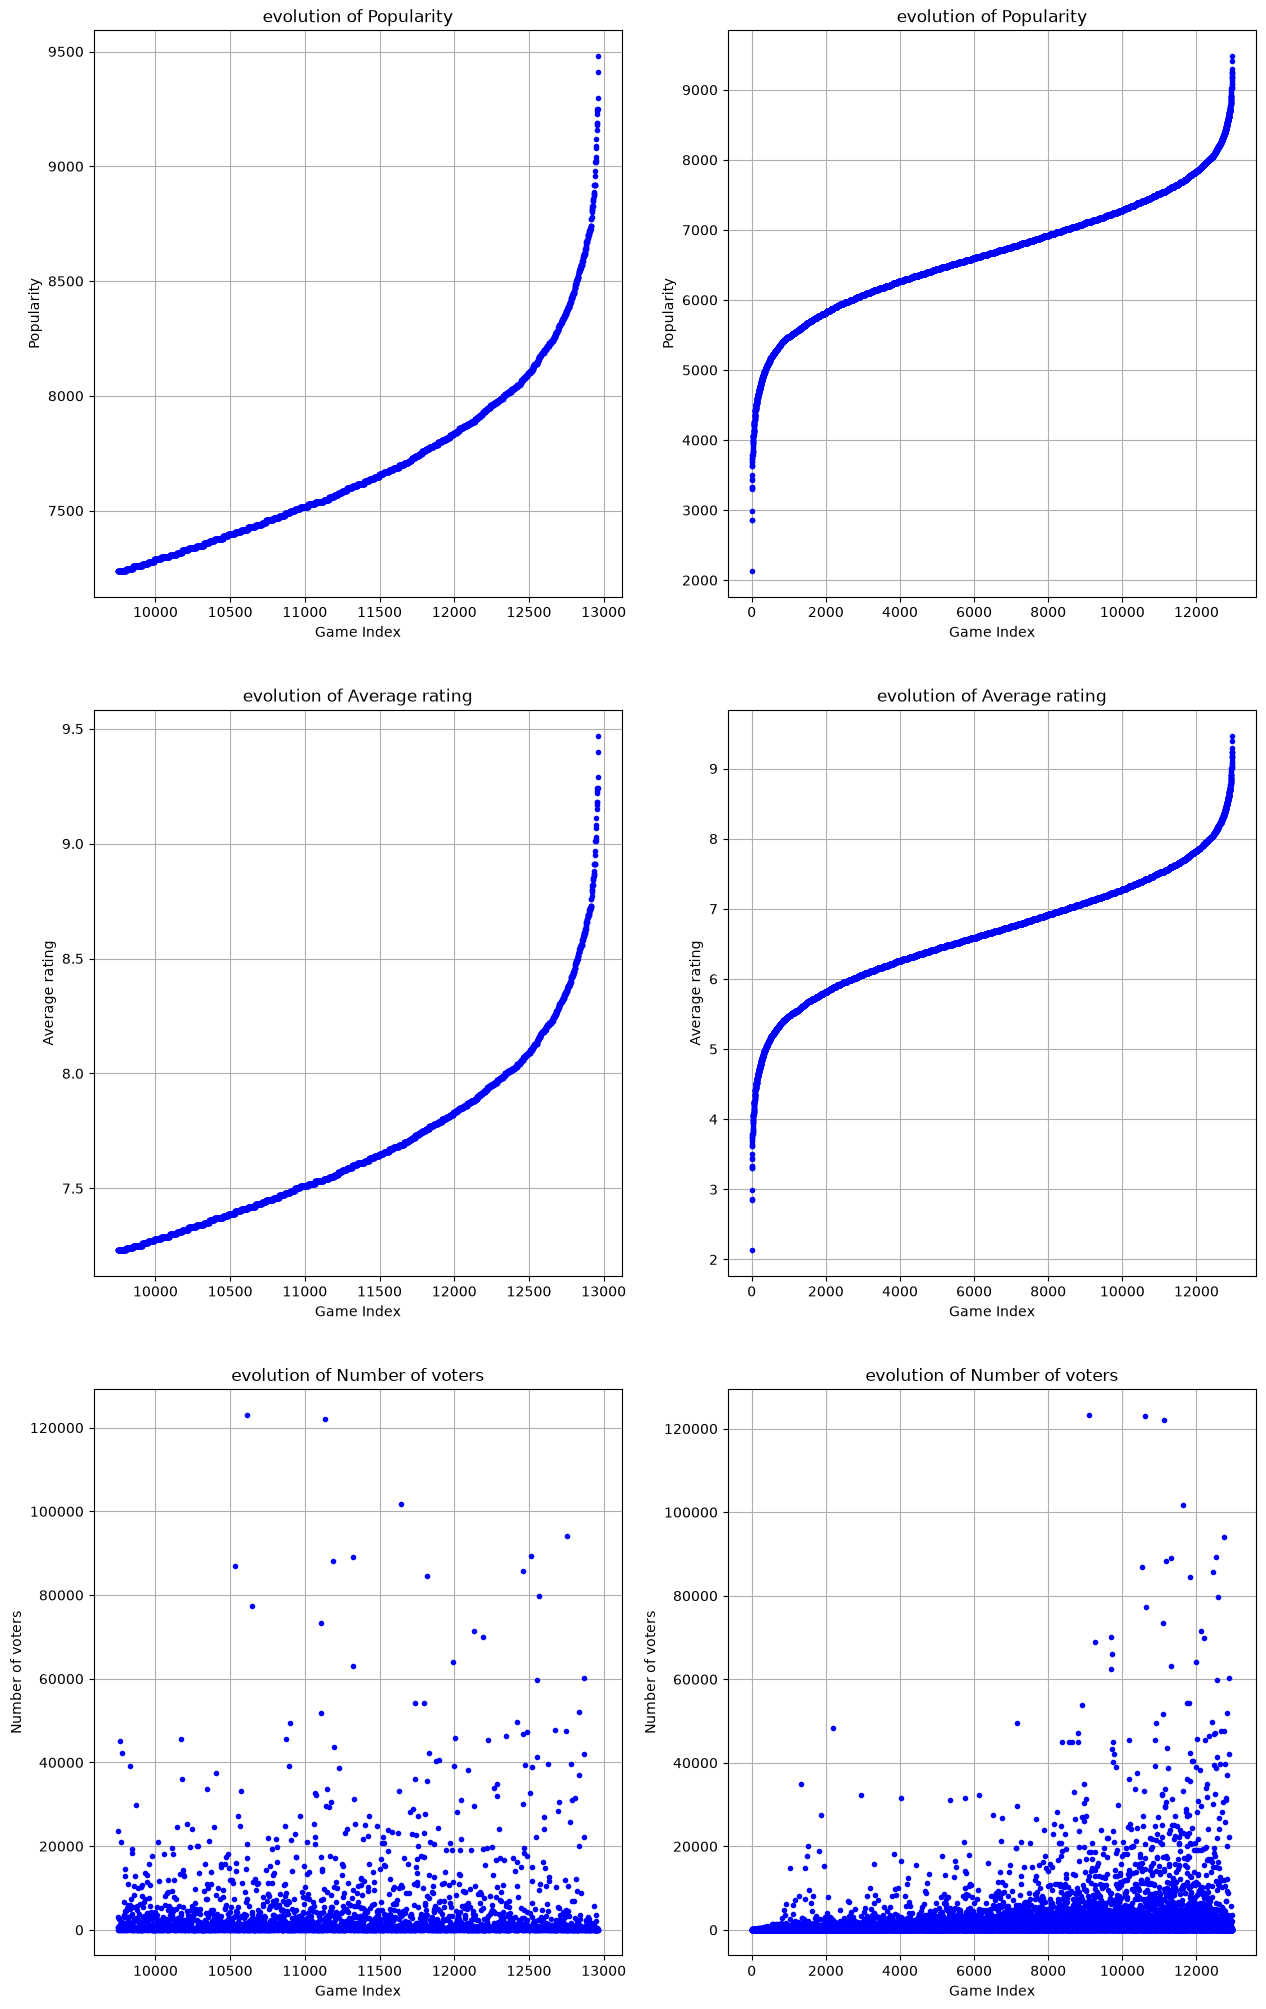

In [100]:
pyplot.figure(figsize=[15, 25])
pyplot.subplot(3, 2, 1)
evolutionGraph(POPULARITY, dataFrame=popularDataFrame, sort=False)
pyplot.subplot(3, 2, 3)
evolutionGraph(AVERAGE_RATING, dataFrame=popularDataFrame, sort=False)
pyplot.subplot(3, 2, 5)
evolutionGraph(NUMBER_VOTE, dataFrame=popularDataFrame, sort=False)

pyplot.subplot(3, 2, 2)
evolutionGraph(POPULARITY, sort=False)
pyplot.subplot(3, 2, 4)
evolutionGraph(AVERAGE_RATING, sort=False)
pyplot.subplot(3, 2, 6)
evolutionGraph(NUMBER_VOTE, sort=False)
pyplot.show()

# hypothese

## seeing the two var use

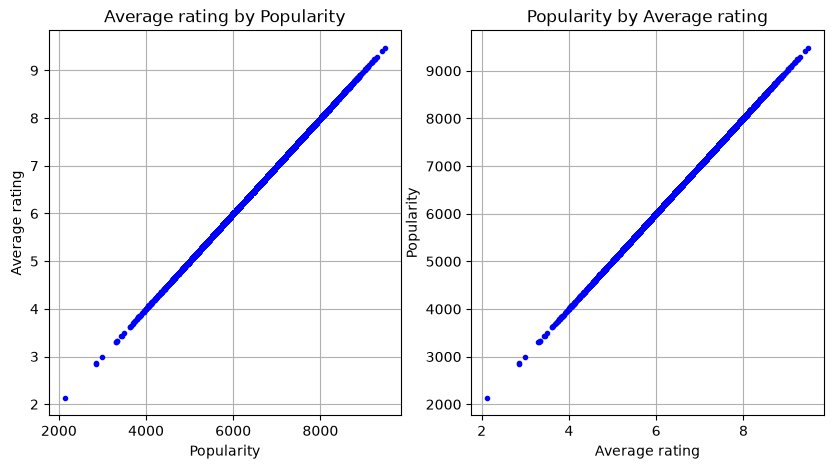

In [101]:
pyplot.figure(figsize=[10, 5])
pyplot.subplot(1, 2, 1)
yByXGraph(POPULARITY, AVERAGE_RATING)
pyplot.subplot(1, 2, 2)
yByXGraph(AVERAGE_RATING, POPULARITY)
pyplot.show()

equation to check if there is a corelation between the two variable (popularity, average rating) :

y = B + B * X + E

H == B1 != 0 y a une corelation

H == B1  = 0 y a pas

In [102]:
result = scipy.stats.linregress(fullDataFrame[POPULARITY], fullDataFrame[AVERAGE_RATING])
print(result)

LinregressResult(slope=np.float64(0.0009990009990009994), intercept=np.float64(-3.552713678800501e-15), rvalue=np.float64(1.0), pvalue=np.float64(0.0), stderr=np.float64(0.0), intercept_stderr=np.float64(0.0))


In [103]:
# 1. Extract parameters
B0 = result.intercept
B1 = result.slope

print("B0: ", B0)
print("B1: ", B1)

B0:  -3.552713678800501e-15
B1:  0.0009990009990009994


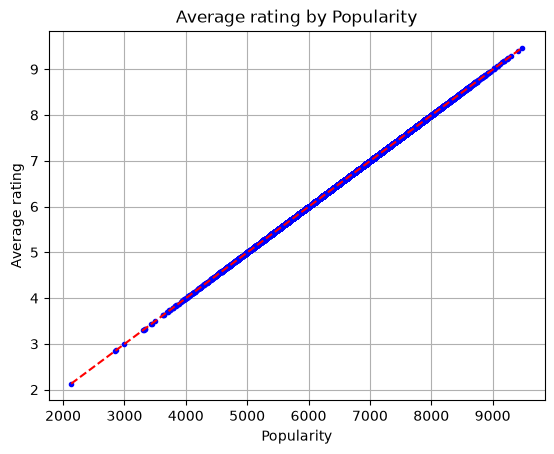

In [104]:
yByXGraph(POPULARITY, AVERAGE_RATING, lineParams=[B0, B1])
pyplot.show()

# choix gouvernance